# CNN Image Interpretation: Understanding What Neural Networks See
## Clinical Objects Edition

This notebook demonstrates how to interpret Convolutional Neural Networks (CNNs) using photographs of everyday clinical equipment. We'll explore several techniques to understand what features a CNN focuses on when making a prediction.

### Why a general-purpose model rather than a diagnostic one?

This notebook uses **ResNet50 pre-trained on ImageNet**, applied to ordinary clinical objects: a stethoscope, a syringe, a pill bottle, an ambulance and a pair of crutches. All five are genuine ImageNet-1k classes, so the pre-trained model recognizes them confidently with no fine-tuning at all.

That is a deliberate choice, and worth being explicit about. What is being taught here is **the interpretability technique**, not the diagnosis. Grad-CAM, saliency maps and feature-map visualization behave in exactly the same way whether the network is separating a stethoscope from a lab coat or a pneumothorax from a normal chest film. Using a model that is already good at its task lets us watch the technique work cleanly, and it keeps the notebook self-contained — no extra dependency, no downloaded medical checkpoint, no data use agreement.

A diagnostic model would make the pictures look more clinical without making the lesson any clearer. Section 14 sets out honestly what *does* change when you point these same tools at real medical images, and why Grad-CAM in particular becomes a genuine safety tool there.

### Why interpret CNN decisions in healthcare?
- **Safety**: Know which pixels drove a prediction, not only what the prediction was
- **Verification**: Confirm the model is keyed on the object itself, not the background, the lighting or a label in the corner
- **Debugging**: Catch spurious correlations before they reach a patient
- **Trust**: Supply the evidence a clinician needs before acting on a model's output

## Learning Objectives
- Understand how CNNs process images through convolutional layers
- Visualize feature maps at different layers
- Use Grad-CAM to see where the model "looks" when it classifies an image
- Generate saliency maps to understand pixel importance
- Compare different interpretability techniques

## Prerequisites
- Basic understanding of neural networks
- Familiarity with PyTorch


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models, transforms
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request
import json
from IPython.display import display, HTML

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check for GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: mps


## 1. Loading a Pre-trained CNN

We'll use ResNet50, a powerful CNN architecture pre-trained on ImageNet (1000 classes). This model has learned to recognize a wide variety of objects through its hierarchical feature extraction.

In [2]:
# Load pre-trained ResNet50 model
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model = model.to(device)
model.eval()

print(f"Model loaded: ResNet50")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

Model loaded: ResNet50
Total parameters: 25,557,032


In [3]:
# Load ImageNet class labels
IMAGENET_LABELS_URL = "https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json"

try:
    with urllib.request.urlopen(IMAGENET_LABELS_URL) as url:
        imagenet_labels = json.loads(url.read().decode())
    print(f"Loaded {len(imagenet_labels)} ImageNet class labels")
except Exception as e:
    print(f"Could not load labels from URL: {e}")
    # Fallback to basic labels
    imagenet_labels = [f"class_{i}" for i in range(1000)]

Loaded 1000 ImageNet class labels


## 2. Image Preprocessing

CNNs require specific input preprocessing. For ImageNet-trained models, we:
1. Resize images to 224x224 pixels
2. Normalize using ImageNet statistics (mean and std of training data)

In [4]:
# Standard ImageNet preprocessing
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def load_image(image_path_or_url):
    """Load an image from a file path or URL."""
    import io
    if image_path_or_url.startswith('http'):
        # Create request with User-Agent header (required by Wikipedia)
        req = urllib.request.Request(
            image_path_or_url,
            headers={'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36'}
        )
        with urllib.request.urlopen(req) as response:
            img_data = response.read()
        img = Image.open(io.BytesIO(img_data)).convert('RGB')
    else:
        img = Image.open(image_path_or_url).convert('RGB')
    return img

def preprocess_image(img):
    """Preprocess image for the model."""
    img_tensor = preprocess(img)
    img_tensor = img_tensor.unsqueeze(0)  # Add batch dimension
    return img_tensor.to(device)

print("Preprocessing functions ready")

Preprocessing functions ready


## 3. Sample Clinical Object Images

We'll work with five photographs of clinical equipment. Each corresponds to a class that really exists in ImageNet-1k, which is why the pre-trained ResNet50 can classify them without any retraining:

| Key | ImageNet class (index) | Why it makes a good demonstration |
|-----|------------------------|-----------------------------------|
| `stethoscope` | `stethoscope` (823) | Thin, high-contrast tubing — a sharp test of how precisely a method localizes |
| `syringe` | `syringe` (845) | Small object, plain background — the easy case, useful as a baseline |
| `pill_bottle` | `pill bottle` (720) | The cap and label carry the class, not the overall silhouette |
| `ambulance` | `ambulance` (407) | Large object where the markings matter more than the shape |
| `crutches` | `crutch` (523) | Object *and* a person in frame — does the model look at the right one? |

The images are free stock photographs from Pexels, fetched at run time. Swap in your own by editing the dictionary below — anything whose subject is an ImageNet class will work.

The ViT notebook (`s3_05_vit_image_interpretation.ipynb`) uses this same set, in this same order, so the two architectures can be compared directly on identical inputs.


Loading: stethoscope


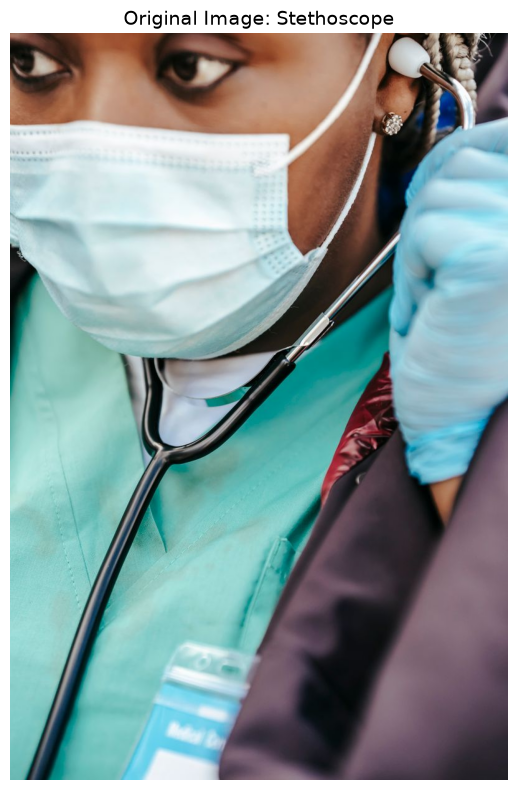


Image size: (800, 1200)
Tensor shape: torch.Size([1, 3, 224, 224])


In [5]:
# Sample clinical object images (free Pexels stock photography).
# Every key below is a real ImageNet-1k class, so the pre-trained model
# recognizes it without fine-tuning.
sample_images = {
    'stethoscope': 'https://images.pexels.com/photos/6098063/pexels-photo-6098063.jpeg?w=800',
    'syringe':     'https://images.pexels.com/photos/6631411/pexels-photo-6631411.jpeg?w=800',
    'pill_bottle': 'https://images.pexels.com/photos/11931275/pexels-photo-11931275.jpeg?w=800',
    'ambulance':   'https://images.pexels.com/photos/8942097/pexels-photo-8942097.jpeg?w=800',
    'crutches':    'https://images.pexels.com/photos/4497823/pexels-photo-4497823.jpeg?w=800',
}

# Load a sample image
selected_image = 'stethoscope'  # Try: 'syringe', 'pill_bottle', 'ambulance', 'crutches'

print(f"Loading: {selected_image}")
original_img = load_image(sample_images[selected_image])
img_tensor = preprocess_image(original_img)

# Display the original image
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(original_img)
ax.axis('off')
ax.set_title(f'Original Image: {selected_image.replace("_", " ").title()}', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nImage size: {original_img.size}")
print(f"Tensor shape: {img_tensor.shape}")


## 4. Basic Classification

Let's see what the model predicts for our image, along with the confidence scores for the top predictions.

Top 5 Predictions:
----------------------------------------
1. stethoscope               86.83%
2. lab coat                   1.36%
3. poke bonnet                0.24%
4. gas mask                   0.18%
5. flute                      0.15%


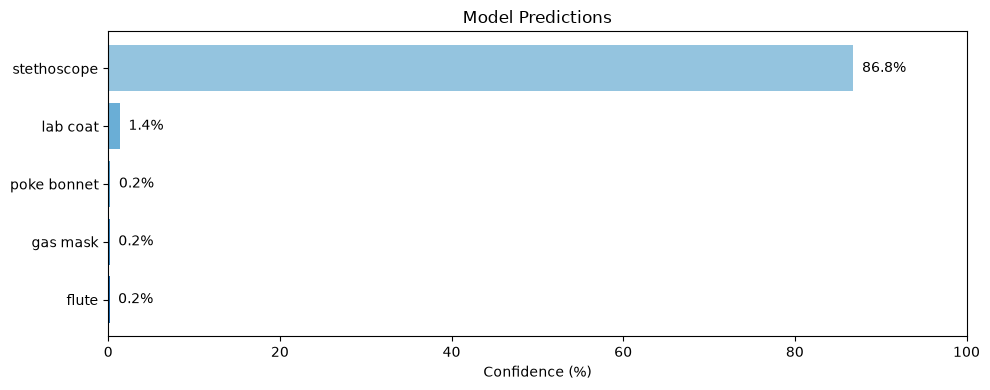

In [6]:
def get_predictions(model, img_tensor, top_k=5):
    """Get top-k predictions from the model."""
    with torch.no_grad():
        outputs = model(img_tensor)
        probabilities = F.softmax(outputs, dim=1)
        top_probs, top_indices = torch.topk(probabilities, top_k)
    
    predictions = []
    for prob, idx in zip(top_probs[0], top_indices[0]):
        predictions.append({
            'class': imagenet_labels[idx.item()],
            'probability': prob.item(),
            'index': idx.item()
        })
    return predictions

# Get predictions
predictions = get_predictions(model, img_tensor)

# Display predictions
print("Top 5 Predictions:")
print("-" * 40)
for i, pred in enumerate(predictions):
    print(f"{i+1}. {pred['class']:25s} {pred['probability']*100:5.2f}%")

# Visualize predictions as bar chart
fig, ax = plt.subplots(figsize=(10, 4))
classes = [p['class'] for p in predictions]
probs = [p['probability'] * 100 for p in predictions]
colors = plt.cm.Blues(np.linspace(0.4, 0.8, len(predictions)))
bars = ax.barh(classes[::-1], probs[::-1], color=colors[::-1])
ax.set_xlabel('Confidence (%)')
ax.set_title('Model Predictions')
ax.set_xlim(0, 100)
for bar, prob in zip(bars, probs[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f'{prob:.1f}%', va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 5. Understanding CNN Architecture

Before diving into interpretation, let's visualize the ResNet50 architecture to understand how information flows through the network.

In [7]:
# Print model architecture summary
def count_parameters(module):
    return sum(p.numel() for p in module.parameters())

print("ResNet50 Layer Structure:")
print("=" * 60)
print(f"{'Layer':<25} {'Output Shape':<20} {'Parameters':>12}")
print("-" * 60)

# Key layers in ResNet50
layer_info = [
    ('conv1', 'Input Conv', '112x112x64'),
    ('bn1 + relu + maxpool', 'Initial Processing', '56x56x64'),
    ('layer1', 'Residual Block 1', '56x56x256'),
    ('layer2', 'Residual Block 2', '28x28x512'),
    ('layer3', 'Residual Block 3', '14x14x1024'),
    ('layer4', 'Residual Block 4', '7x7x2048'),
    ('avgpool', 'Global Average Pool', '1x1x2048'),
    ('fc', 'Fully Connected', '1000 classes'),
]

for name, desc, shape in layer_info:
    print(f"{desc:<25} {shape:<20}")

print("=" * 60)
print(f"\nTotal Parameters: {sum(p.numel() for p in model.parameters()):,}")

ResNet50 Layer Structure:
Layer                     Output Shape           Parameters
------------------------------------------------------------
Input Conv                112x112x64          
Initial Processing        56x56x64            
Residual Block 1          56x56x256           
Residual Block 2          28x28x512           
Residual Block 3          14x14x1024          
Residual Block 4          7x7x2048            
Global Average Pool       1x1x2048            
Fully Connected           1000 classes        

Total Parameters: 25,557,032


## 6. Feature Map Visualization

Let's visualize what the CNN "sees" at different layers. Early layers detect simple features (edges, colors), while deeper layers capture complex patterns (textures, object parts).

In [8]:
class FeatureExtractor:
    """Extract feature maps from intermediate CNN layers."""
    def __init__(self, model, target_layers):
        self.model = model
        self.target_layers = target_layers
        self.features = {}
        self.hooks = []
        
        # Register hooks for target layers
        for name, module in model.named_modules():
            if name in target_layers:
                hook = module.register_forward_hook(self._get_hook(name))
                self.hooks.append(hook)
    
    def _get_hook(self, name):
        def hook(module, input, output):
            self.features[name] = output.detach()
        return hook
    
    def __call__(self, x):
        self.features = {}
        output = self.model(x)
        return output, self.features
    
    def remove_hooks(self):
        for hook in self.hooks:
            hook.remove()

# Target layers to visualize
target_layers = ['conv1', 'layer1', 'layer2', 'layer3', 'layer4']
extractor = FeatureExtractor(model, target_layers)

# Extract features
output, features = extractor(img_tensor)

print("Feature map shapes at each layer:")
for name, feat in features.items():
    print(f"  {name}: {feat.shape}")

Feature map shapes at each layer:
  conv1: torch.Size([1, 64, 112, 112])
  layer1: torch.Size([1, 256, 56, 56])
  layer2: torch.Size([1, 512, 28, 28])
  layer3: torch.Size([1, 1024, 14, 14])
  layer4: torch.Size([1, 2048, 7, 7])


Early layer (conv1) - detects simple edges and colors:


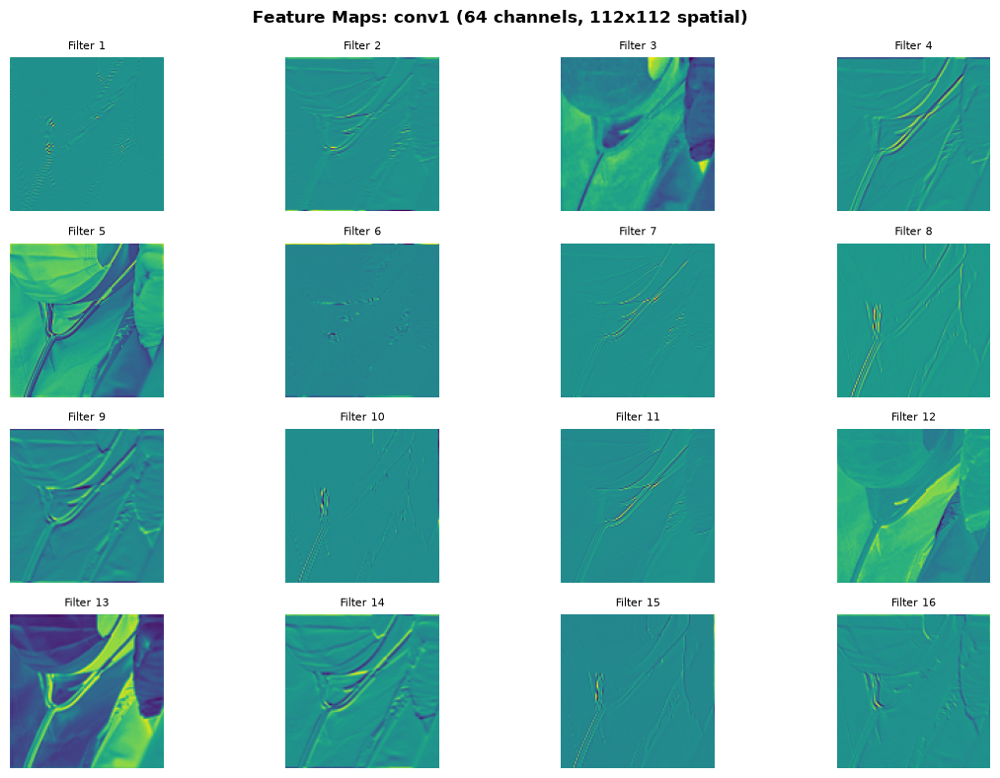


Middle layer (layer2) - detects textures and patterns:


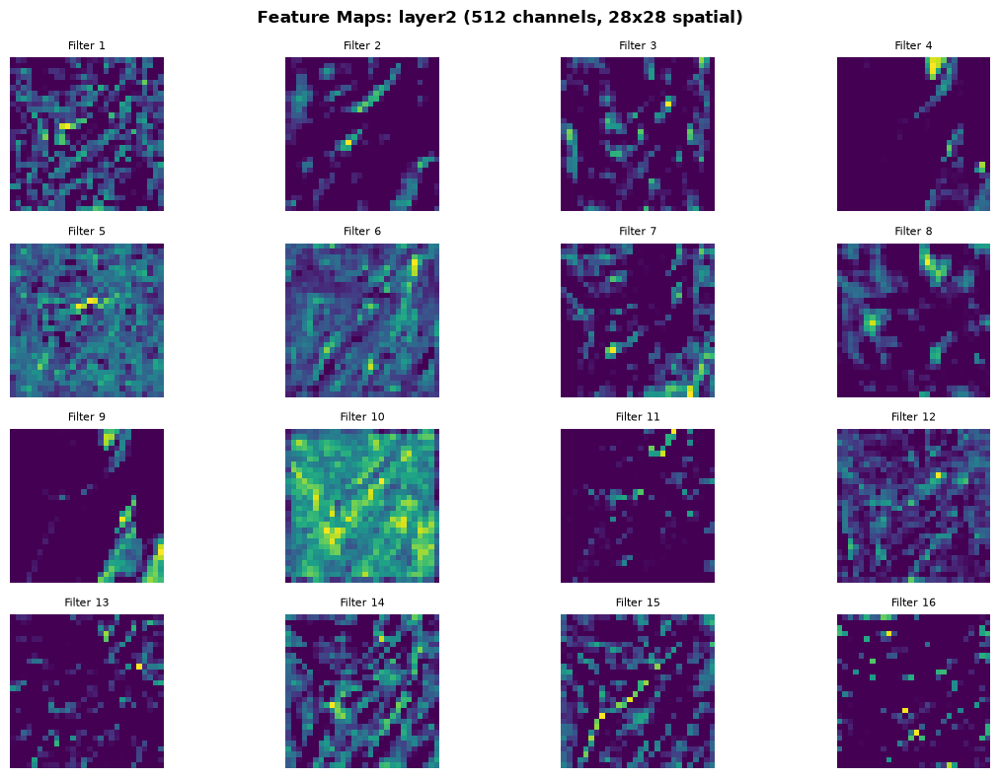


Deep layer (layer4) - detects high-level features and object parts:


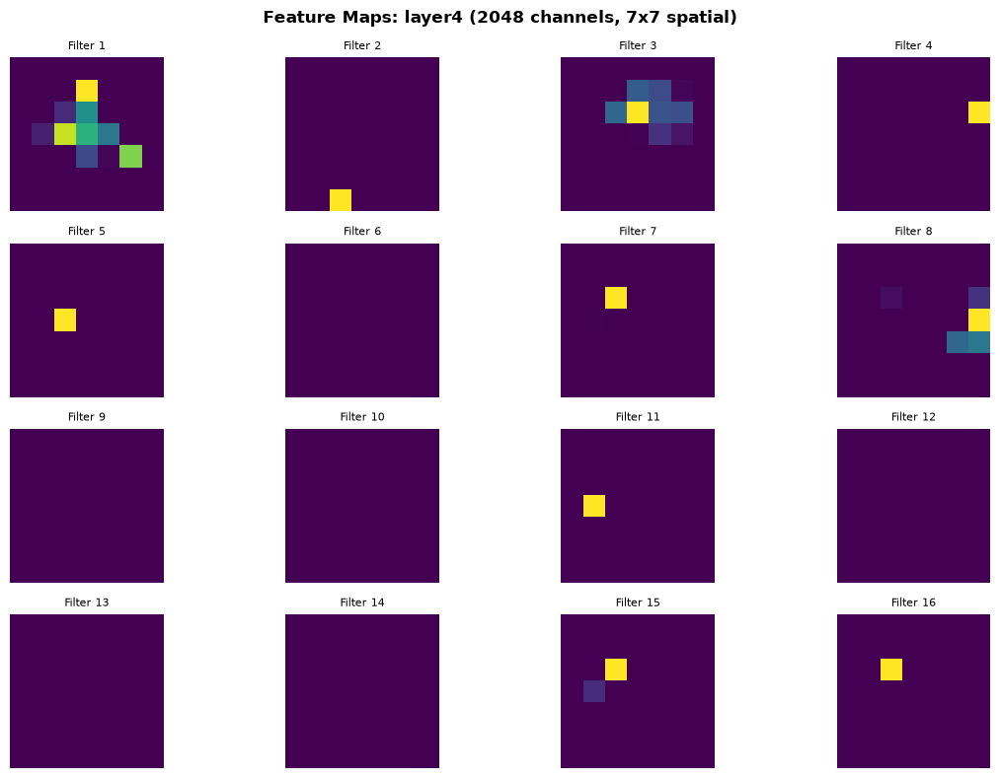

In [9]:
def visualize_feature_maps(features, layer_name, num_maps=16, figsize=(12, 8)):
    """Visualize feature maps from a specific layer."""
    feat = features[layer_name][0].cpu().numpy()  # Remove batch dimension
    
    # Select subset of feature maps
    num_channels = min(num_maps, feat.shape[0])
    
    # Calculate grid size
    cols = 4
    rows = (num_channels + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()
    
    for i in range(num_channels):
        ax = axes[i]
        # Normalize feature map for visualization
        feat_map = feat[i]
        feat_map = (feat_map - feat_map.min()) / (feat_map.max() - feat_map.min() + 1e-8)
        ax.imshow(feat_map, cmap='viridis')
        ax.axis('off')
        ax.set_title(f'Filter {i+1}', fontsize=8)
    
    # Hide unused subplots
    for i in range(num_channels, len(axes)):
        axes[i].axis('off')
    
    plt.suptitle(f'Feature Maps: {layer_name} ({feat.shape[0]} channels, {feat.shape[1]}x{feat.shape[2]} spatial)', 
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Visualize feature maps at different depths
print("Early layer (conv1) - detects simple edges and colors:")
visualize_feature_maps(features, 'conv1', num_maps=16)

print("\nMiddle layer (layer2) - detects textures and patterns:")
visualize_feature_maps(features, 'layer2', num_maps=16)

print("\nDeep layer (layer4) - detects high-level features and object parts:")
visualize_feature_maps(features, 'layer4', num_maps=16)

## 7. Grad-CAM: Gradient-weighted Class Activation Mapping

Grad-CAM is a powerful technique that shows which regions of an image the CNN focuses on when making a particular prediction. It uses the gradients flowing into the final convolutional layer to produce a heatmap highlighting important regions.

### How Grad-CAM Works:
1. Forward pass the image through the network
2. Get the score for the target class
3. Backpropagate to get gradients of the target class score with respect to feature maps
4. Global average pool the gradients to get importance weights
5. Weight the feature maps and sum them
6. Apply ReLU to get the final heatmap

In [10]:
class GradCAM:
    """Grad-CAM implementation for CNN interpretation."""
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register hooks
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)
    
    def _save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def __call__(self, x, target_class=None):
        """Generate Grad-CAM heatmap."""
        # Forward pass
        self.model.zero_grad()
        output = self.model(x)
        
        # If no target class specified, use the predicted class
        if target_class is None:
            target_class = output.argmax(dim=1).item()
        
        # Backward pass for target class
        one_hot = torch.zeros_like(output)
        one_hot[0, target_class] = 1
        output.backward(gradient=one_hot, retain_graph=True)
        
        # Global average pooling of gradients
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        
        # Weighted sum of activations
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        
        # Apply ReLU and normalize
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        
        # Resize to input image size
        cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)
        
        return cam[0, 0].cpu().numpy(), target_class

# Create Grad-CAM for the last convolutional layer
grad_cam = GradCAM(model, model.layer4[-1])
print("Grad-CAM initialized for layer4 (final convolutional block)")

Grad-CAM initialized for layer4 (final convolutional block)


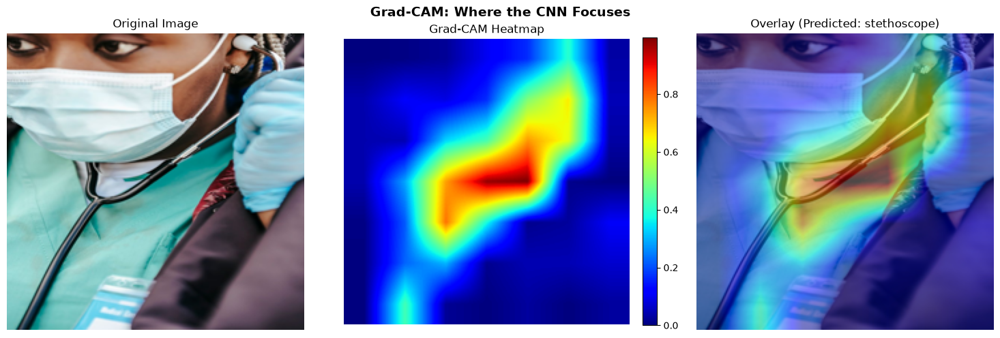


The CNN focuses on the highlighted regions to identify: stethoscope


In [11]:
def visualize_gradcam(img, img_tensor, grad_cam, target_class=None, alpha=0.5):
    """Visualize Grad-CAM heatmap overlaid on the original image."""
    # Generate heatmap
    heatmap, pred_class = grad_cam(img_tensor, target_class)
    
    # Resize original image to 224x224 for overlay
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized) / 255.0
    
    # Create colored heatmap
    heatmap_colored = plt.cm.jet(heatmap)[:, :, :3]
    
    # Overlay heatmap on image
    overlay = alpha * heatmap_colored + (1 - alpha) * img_array
    overlay = np.clip(overlay, 0, 1)
    
    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img_resized)
    axes[0].set_title('Original Image', fontsize=12)
    axes[0].axis('off')
    
    # Heatmap
    im = axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title('Grad-CAM Heatmap', fontsize=12)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # Overlay
    axes[2].imshow(overlay)
    axes[2].set_title(f'Overlay (Predicted: {imagenet_labels[pred_class]})', fontsize=12)
    axes[2].axis('off')
    
    plt.suptitle('Grad-CAM: Where the CNN Focuses', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return heatmap, pred_class

# Visualize Grad-CAM for the predicted class
heatmap, pred_class = visualize_gradcam(original_img, img_tensor, grad_cam)
print(f"\nThe CNN focuses on the highlighted regions to identify: {imagenet_labels[pred_class]}")

## 8. Grad-CAM for Different Classes

We can also see what the CNN would focus on if it were looking for a different class. This helps us understand how the model distinguishes between different objects.

Comparing Grad-CAM for top 3 predicted classes:


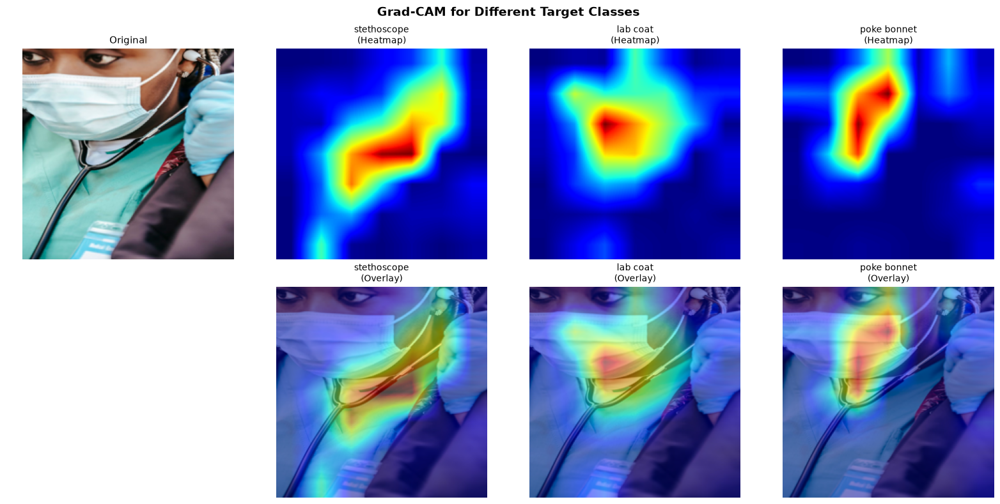

In [12]:
def compare_gradcam_classes(img, img_tensor, grad_cam, class_indices, class_names=None):
    """Compare Grad-CAM heatmaps for different target classes."""
    n_classes = len(class_indices)
    fig, axes = plt.subplots(2, n_classes + 1, figsize=(4 * (n_classes + 1), 8))
    
    # Resize original image
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized) / 255.0
    
    # Show original image in first column
    axes[0, 0].imshow(img_resized)
    axes[0, 0].set_title('Original', fontsize=11)
    axes[0, 0].axis('off')
    axes[1, 0].axis('off')
    
    # Generate and show heatmaps for each class
    for i, class_idx in enumerate(class_indices):
        heatmap, _ = grad_cam(img_tensor, class_idx)
        heatmap_colored = plt.cm.jet(heatmap)[:, :, :3]
        overlay = 0.5 * heatmap_colored + 0.5 * img_array
        overlay = np.clip(overlay, 0, 1)
        
        # Class name
        name = class_names[i] if class_names else imagenet_labels[class_idx]
        
        # Heatmap
        axes[0, i + 1].imshow(heatmap, cmap='jet')
        axes[0, i + 1].set_title(f'{name}\n(Heatmap)', fontsize=10)
        axes[0, i + 1].axis('off')
        
        # Overlay
        axes[1, i + 1].imshow(overlay)
        axes[1, i + 1].set_title(f'{name}\n(Overlay)', fontsize=10)
        axes[1, i + 1].axis('off')
    
    plt.suptitle('Grad-CAM for Different Target Classes', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Compare top 3 predicted classes
top_classes = [pred['index'] for pred in predictions[:3]]
top_names = [pred['class'] for pred in predictions[:3]]

print("Comparing Grad-CAM for top 3 predicted classes:")
compare_gradcam_classes(original_img, img_tensor, grad_cam, top_classes, top_names)

## 9. Saliency Maps

Saliency maps show which pixels have the most influence on the model's prediction. Unlike Grad-CAM, which operates on feature maps, saliency maps work directly with input pixels.

### How Saliency Maps Work:
1. Forward pass the image
2. Compute gradients of the target class score with respect to input pixels
3. Take the maximum absolute gradient across color channels
4. The resulting map shows pixel importance

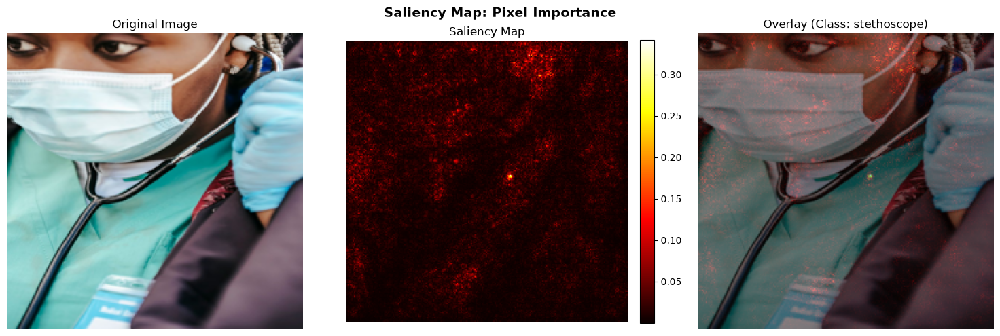


Brighter pixels have more influence on the prediction.


In [13]:
def compute_saliency_map(model, img_tensor, target_class=None):
    """Compute saliency map using vanilla gradients."""
    # Enable gradients for input
    img_tensor = img_tensor.clone().requires_grad_(True)
    
    # Forward pass
    model.zero_grad()
    output = model(img_tensor)
    
    # If no target class, use predicted class
    if target_class is None:
        target_class = output.argmax(dim=1).item()
    
    # Backward pass
    one_hot = torch.zeros_like(output)
    one_hot[0, target_class] = 1
    output.backward(gradient=one_hot)
    
    # Get saliency map (max across color channels)
    saliency = img_tensor.grad.abs().squeeze(0)
    saliency, _ = saliency.max(dim=0)
    
    return saliency.cpu().numpy(), target_class

def visualize_saliency(img, img_tensor, model, target_class=None):
    """Visualize saliency map."""
    saliency, pred_class = compute_saliency_map(model, img_tensor, target_class)
    
    # Resize original image
    img_resized = img.resize((224, 224))
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Original image
    axes[0].imshow(img_resized)
    axes[0].set_title('Original Image', fontsize=12)
    axes[0].axis('off')
    
    # Saliency map
    im = axes[1].imshow(saliency, cmap='hot')
    axes[1].set_title('Saliency Map', fontsize=12)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # Overlay
    axes[2].imshow(img_resized)
    axes[2].imshow(saliency, cmap='hot', alpha=0.5)
    axes[2].set_title(f'Overlay (Class: {imagenet_labels[pred_class]})', fontsize=12)
    axes[2].axis('off')
    
    plt.suptitle('Saliency Map: Pixel Importance', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return saliency

# Visualize saliency map
saliency = visualize_saliency(original_img, img_tensor, model)
print("\nBrighter pixels have more influence on the prediction.")

## 10. Comparison of Interpretation Methods

Let's compare all our interpretation methods side by side to understand their differences.

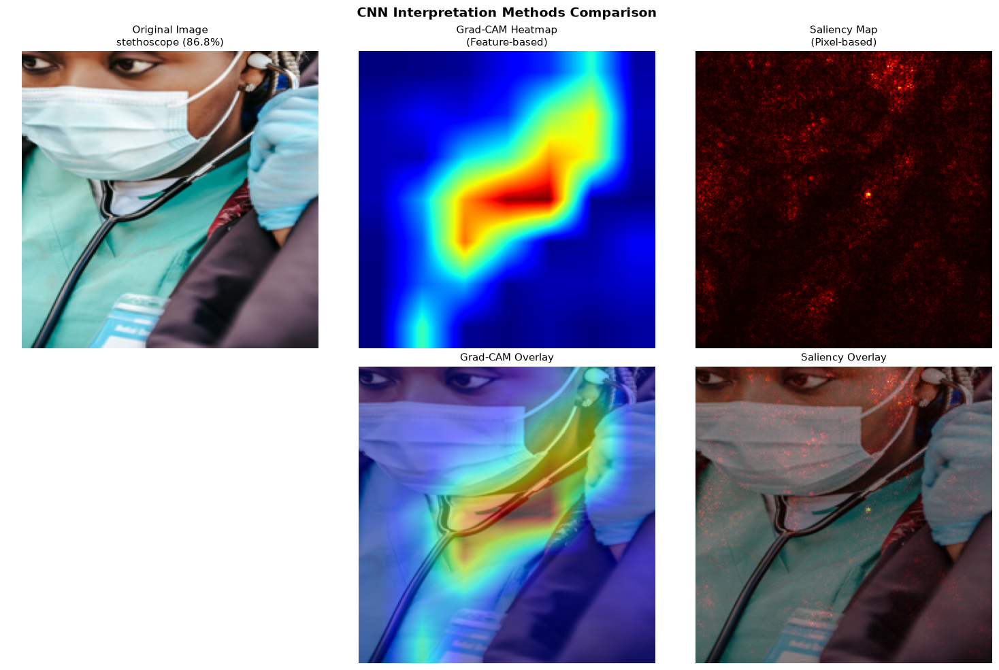


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients


In [14]:
def comprehensive_interpretation(img, img_tensor, model, grad_cam):
    """Generate comprehensive visualization comparing all interpretation methods."""
    # Get prediction
    with torch.no_grad():
        output = model(img_tensor)
        pred_class = output.argmax(dim=1).item()
        prob = F.softmax(output, dim=1)[0, pred_class].item()
    
    # Resize original image
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized) / 255.0
    
    # Generate interpretations
    gradcam_heatmap, _ = grad_cam(img_tensor, pred_class)
    saliency, _ = compute_saliency_map(model, img_tensor, pred_class)
    
    # Normalize saliency for visualization
    saliency_norm = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)
    
    # Create figure
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Row 1: Original and heatmaps
    axes[0, 0].imshow(img_resized)
    axes[0, 0].set_title(f'Original Image\n{imagenet_labels[pred_class]} ({prob*100:.1f}%)', fontsize=11)
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(gradcam_heatmap, cmap='jet')
    axes[0, 1].set_title('Grad-CAM Heatmap\n(Feature-based)', fontsize=11)
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(saliency_norm, cmap='hot')
    axes[0, 2].set_title('Saliency Map\n(Pixel-based)', fontsize=11)
    axes[0, 2].axis('off')
    
    # Row 2: Overlays
    axes[1, 0].axis('off')
    
    # Grad-CAM overlay
    gradcam_colored = plt.cm.jet(gradcam_heatmap)[:, :, :3]
    gradcam_overlay = 0.5 * gradcam_colored + 0.5 * img_array
    axes[1, 1].imshow(np.clip(gradcam_overlay, 0, 1))
    axes[1, 1].set_title('Grad-CAM Overlay', fontsize=11)
    axes[1, 1].axis('off')
    
    # Saliency overlay
    axes[1, 2].imshow(img_resized)
    axes[1, 2].imshow(saliency_norm, cmap='hot', alpha=0.5)
    axes[1, 2].set_title('Saliency Overlay', fontsize=11)
    axes[1, 2].axis('off')
    
    plt.suptitle('CNN Interpretation Methods Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print("\n" + "="*60)
    print("Summary of Interpretation Methods:")
    print("="*60)
    print("\n1. Grad-CAM:")
    print("   - Shows REGIONS the CNN focuses on")
    print("   - Coarse but class-specific")
    print("   - Based on final convolutional layer activations")
    print("\n2. Saliency Maps:")
    print("   - Shows which PIXELS influence the prediction")
    print("   - Fine-grained but can be noisy")
    print("   - Based on input gradients")

comprehensive_interpretation(original_img, img_tensor, model, grad_cam)

## 11. Analyze All Five Objects

Let's run every interpretation method over all five images and see how the CNN's focus shifts from one object to the next.


Analyzing all five clinical objects...
Watch how the CNN's focus shifts from one object to the next.


Analyzing: STETHOSCOPE

Top 5 Predictions:
  1. stethoscope: 86.8%
  2. lab coat: 1.4%
  3. poke bonnet: 0.2%
  4. gas mask: 0.2%
  5. flute: 0.2%


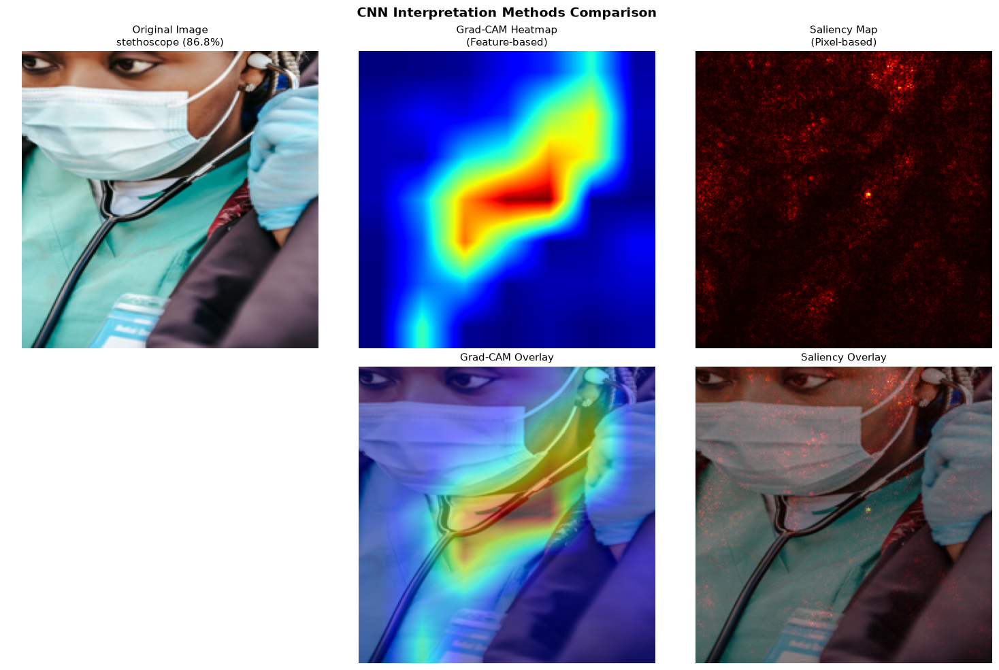


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients

Analyzing: SYRINGE

Top 5 Predictions:
  1. syringe: 78.8%
  2. screwdriver: 1.1%
  3. paintbrush: 1.1%
  4. projectile: 0.6%
  5. missile: 0.5%


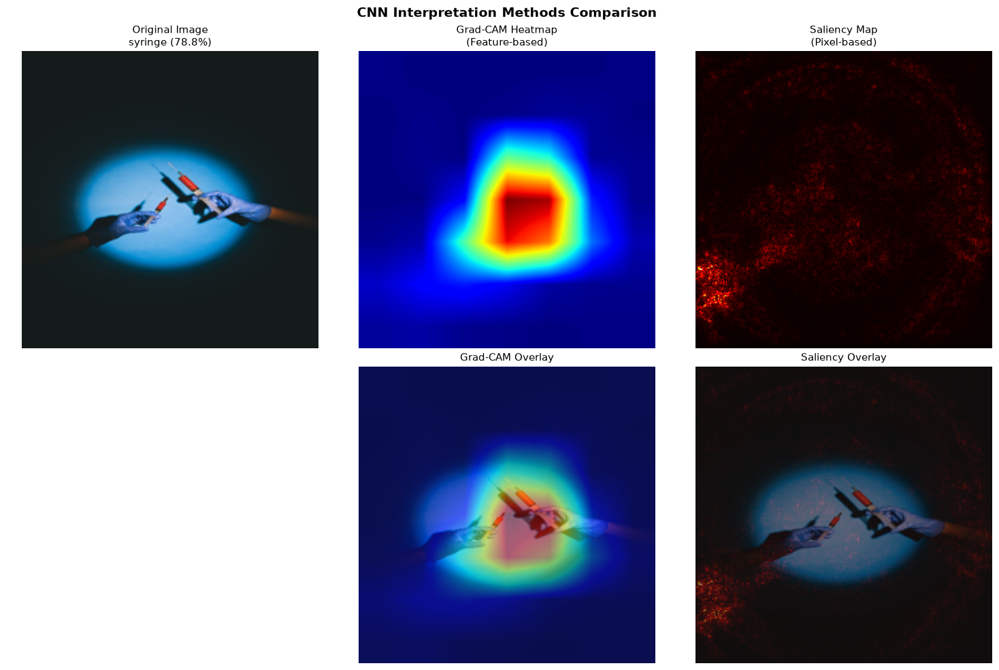


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients

Analyzing: PILL BOTTLE

Top 5 Predictions:
  1. pill bottle: 56.5%
  2. lotion: 0.7%
  3. sunscreen: 0.7%
  4. measuring cup: 0.5%
  5. piggy bank: 0.4%


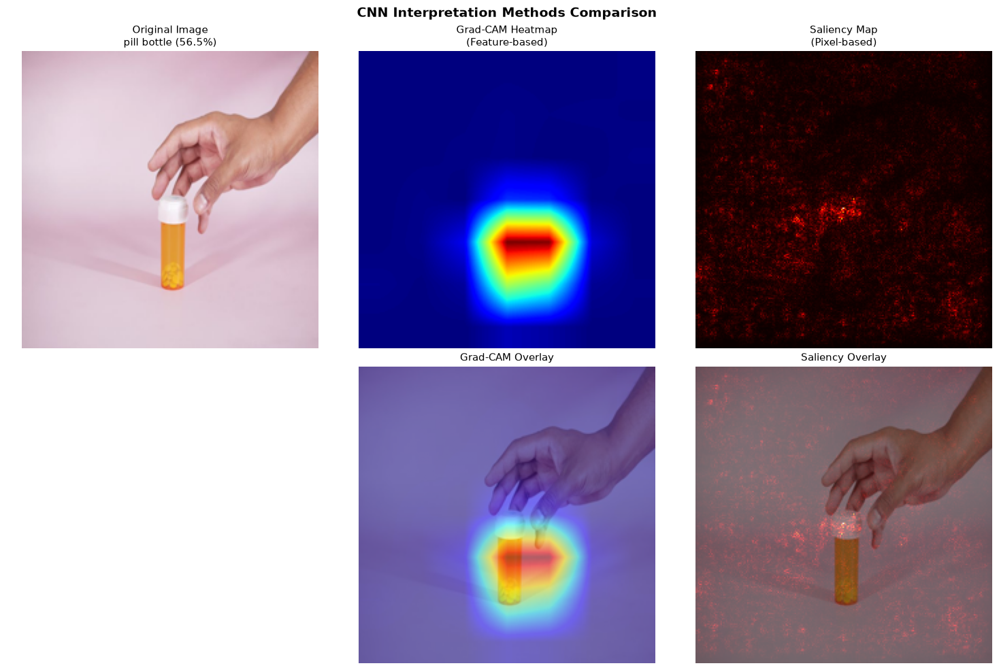


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients

Analyzing: AMBULANCE

Top 5 Predictions:
  1. ambulance: 57.4%
  2. police van: 4.0%
  3. minibus: 2.7%
  4. minivan: 1.0%
  5. taxicab: 0.7%


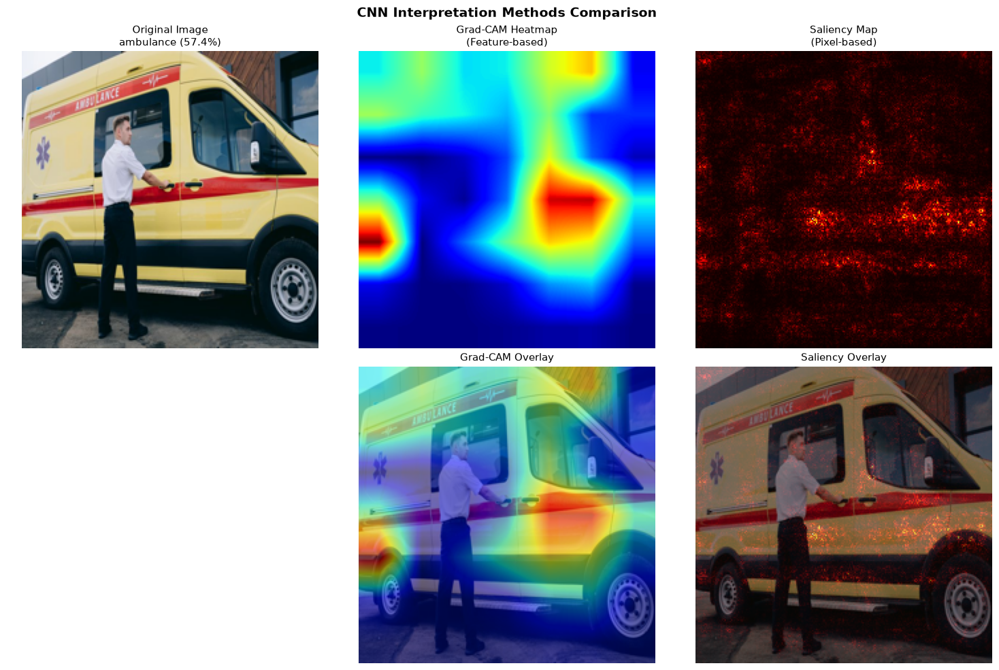


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients

Analyzing: CRUTCHES

Top 5 Predictions:
  1. crutch: 54.7%
  2. Band-Aid: 4.1%
  3. diaper: 1.1%
  4. miniskirt: 0.6%
  5. sock: 0.5%


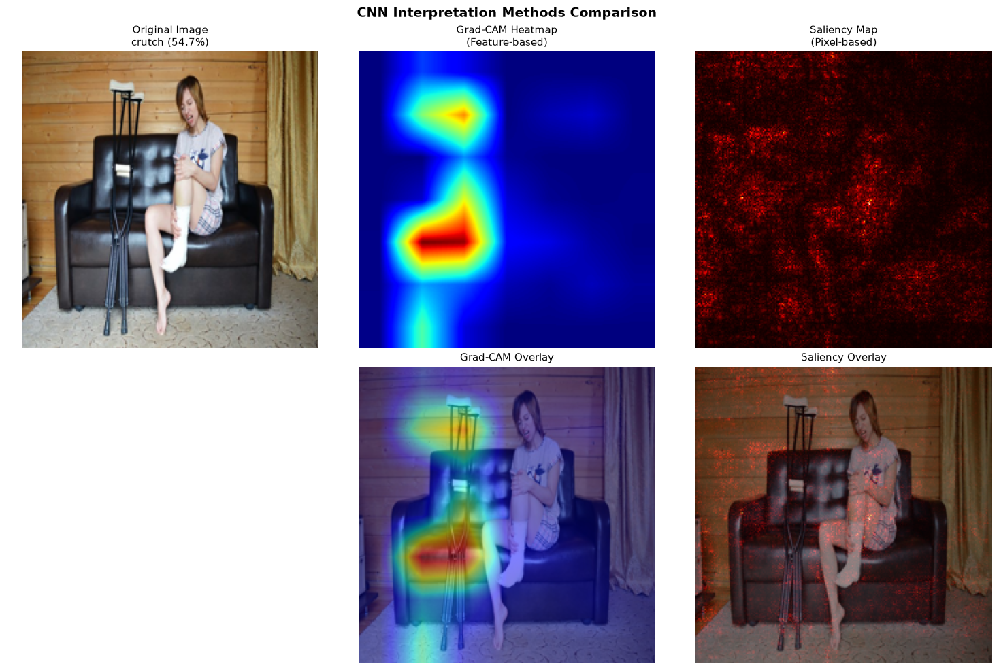


Summary of Interpretation Methods:

1. Grad-CAM:
   - Shows REGIONS the CNN focuses on
   - Coarse but class-specific
   - Based on final convolutional layer activations

2. Saliency Maps:
   - Shows which PIXELS influence the prediction
   - Fine-grained but can be noisy
   - Based on input gradients


In [15]:
def analyze_clinical_image(image_key):
    """Analyze one clinical object image with all interpretation methods."""
    print(f"\n{'='*60}")
    print(f"Analyzing: {image_key.replace('_', ' ').upper()}")
    print('='*60)

    # Load and preprocess
    img = load_image(sample_images[image_key])
    tensor = preprocess_image(img)

    # Get predictions
    preds = get_predictions(model, tensor, top_k=5)
    print("\nTop 5 Predictions:")
    for i, p in enumerate(preds):
        print(f"  {i+1}. {p['class']}: {p['probability']*100:.1f}%")

    # Comprehensive visualization
    comprehensive_interpretation(img, tensor, model, grad_cam)

# Analyze every object in the sample set
print("Analyzing all five clinical objects...")
print("Watch how the CNN's focus shifts from one object to the next.\n")

for key in sample_images.keys():
    analyze_clinical_image(key)


## 12. Grad-CAM at Different Layers

Let's see how the attention differs across different depths of the network.

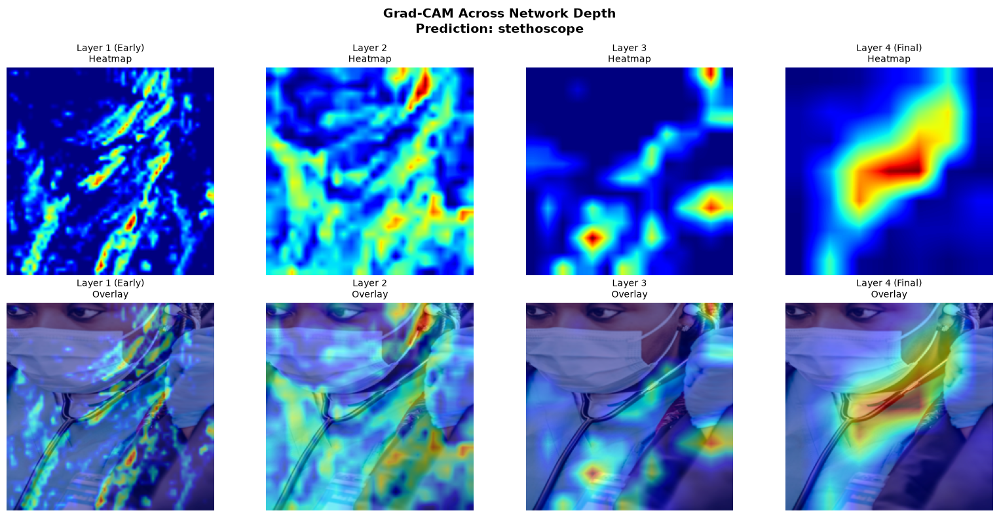


Observation:
- Early layers have more diffuse attention (detecting edges/textures everywhere)
- Later layers have more focused attention (localizing the object)


In [16]:
def gradcam_across_layers(img, img_tensor, model):
    """Visualize Grad-CAM at different network depths."""
    # Define layers to analyze
    layer_configs = [
        ('layer1', model.layer1[-1], 'Layer 1 (Early)'),
        ('layer2', model.layer2[-1], 'Layer 2'),
        ('layer3', model.layer3[-1], 'Layer 3'),
        ('layer4', model.layer4[-1], 'Layer 4 (Final)'),
    ]
    
    # Resize original image
    img_resized = img.resize((224, 224))
    img_array = np.array(img_resized) / 255.0
    
    fig, axes = plt.subplots(2, len(layer_configs), figsize=(16, 8))
    
    for i, (name, layer, title) in enumerate(layer_configs):
        # Create Grad-CAM for this layer
        gc = GradCAM(model, layer)
        heatmap, pred_class = gc(img_tensor)
        
        # Heatmap
        axes[0, i].imshow(heatmap, cmap='jet')
        axes[0, i].set_title(f'{title}\nHeatmap', fontsize=10)
        axes[0, i].axis('off')
        
        # Overlay
        heatmap_colored = plt.cm.jet(heatmap)[:, :, :3]
        overlay = 0.5 * heatmap_colored + 0.5 * img_array
        axes[1, i].imshow(np.clip(overlay, 0, 1))
        axes[1, i].set_title(f'{title}\nOverlay', fontsize=10)
        axes[1, i].axis('off')
    
    plt.suptitle(f'Grad-CAM Across Network Depth\nPrediction: {imagenet_labels[pred_class]}', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\nObservation:")
    print("- Early layers have more diffuse attention (detecting edges/textures everywhere)")
    print("- Later layers have more focused attention (localizing the object)")

gradcam_across_layers(original_img, img_tensor, model)

## 13. Key Takeaways

### What we learned

1. **CNNs learn hierarchical features.** Early layers detect simple patterns (edges, texture, colour gradients), while deeper layers respond to complete object parts — the bell and tubing of a stethoscope, the plunger and barrel of a syringe, the cap and label of a pill bottle.

2. **Grad-CAM gives class-discriminative localization.**
   - It shows which regions separate one class from another, not merely which regions are busy
   - Asking for a *different* target class moves the heatmap, which is what makes it diagnostic rather than decorative
   - Run at different depths it gives different granularities: diffuse early, tightly localized at the last block

3. **Saliency maps show pixel-level importance.**
   - Fine-grained, but noticeably noisy
   - Useful when you need to know which exact edges mattered, not just which region

4. **Interpretation is how you audit a model.** In the crutches image the object shares the frame with a person. Grad-CAM answers a question the accuracy score cannot: is the model keyed on the crutches, or on the person, or on the sofa behind them? A model can be right for entirely the wrong reason, and a confusion matrix will never tell you so.

### Limitations to keep in mind
- These methods show correlation, not causation. A bright heatmap over the tubing does not prove the model "understands" auscultation.
- Grad-CAM's resolution is bounded by the feature map it is computed from — at the last ResNet block that is 7x7 upsampled to 224x224, so the heatmap is inherently coarse.
- Background and context genuinely influence predictions. That is sometimes a bug and sometimes the model legitimately using scene information; the heatmap alone cannot tell you which.
- Different interpretability methods disagree with each other. Treat agreement between Grad-CAM and saliency as weak corroboration, not proof.


## 14. What Changes for Real Medical Imaging

Everything above transfers as a *technique*. Four things change in practice, and they change a lot.

**1. The model is domain-specific.** ImageNet weights are a poor starting point for radiology. Production systems fine-tune on in-domain data (CheXNet-style DenseNet backbones for chest radiographs, nnU-Net for volumetric segmentation) or start from a medical foundation model. The hook you register for Grad-CAM is identical; only the layer you hook changes.

**2. The input is DICOM, not JPEG.** A DICOM file is a 12–16 bit single-channel pixel array plus a metadata header, not an 8-bit RGB photograph. That brings windowing and levelling (the same pixels can be rendered as lung, mediastinal or bone windows — and the model's answer can change with the window), photometric interpretation, per-manufacturer rescale slopes, and a header full of protected health information that has to be stripped before the image goes anywhere. `pydicom` handles the reading; the de-identification is a policy problem, not a library call.

**3. The resolution is far higher.** A chest radiograph is roughly 2500x2500 pixels and a digitized pathology slide can exceed 100,000 pixels on a side. Downsampling to 224x224 destroys exactly the fine detail that carries the finding — a 3 mm nodule is sub-pixel at that scale. Real pipelines tile the image, run the model per tile, and aggregate; interpretability maps have to be stitched back together across tiles, and a coarse 7x7 Grad-CAM per tile is a much weaker instrument than it looks here.

**4. Grad-CAM stops being a teaching aid and becomes a safety instrument.** This is the important one. Published audits of chest-radiograph classifiers have repeatedly found models achieving excellent test AUC while keying on things that have nothing to do with the pathology:

- **Laterality and orientation markers** — the small radio-opaque "L"/"R" token placed by the radiographer
- **Scanner and protocol artefacts** — a model that learns to recognize the portable machine wheeled to the sickest patients has learned *acuity*, not disease
- **Chest drains, pacemakers and ECG leads** — hardware that is present *because* the patient was already diagnosed and treated, which leaks the label
- **Text burned into the image**, and **body position**, since sicker patients are imaged supine

Every one of those is invisible in the accuracy number and obvious the moment you overlay a Grad-CAM. That is why regulators and hospital review boards ask for saliency evidence, and why "the heatmap sits on the pathology" is part of the acceptance criteria rather than a nice-to-have. It is also why a heatmap should never be shown to a clinician as an explanation of *why* — it localizes what the model responded to, which is a weaker and more useful claim.

**Where to get real data.** Most public medical imaging datasets require registration and a data use agreement, and several forbid redistribution or commercial use — read the licence before you download, and never commit the images to a repository.

| Dataset | Modality | Notes |
|---------|----------|-------|
| **NIH ChestX-ray14** | Chest radiographs | 112,120 images, 30,805 patients, 14 labels. Openly downloadable. Labels were NLP-mined from reports and are known to be noisy. |
| **CheXpert** (Stanford) | Chest radiographs | 224,316 images, 65,240 patients. Registration and a data use agreement required. Includes explicit uncertainty labels. |
| **MIMIC-CXR** (MIT/BIDMC) | Chest radiographs + free-text reports | Requires PhysioNet credentialing and CITI human-subjects training. The most realistic option, and the slowest to get access to. |
| **ISIC Archive** | Dermoscopy | The standard skin-lesion benchmark. A well-documented cautionary tale: early models learned to key on the surgical skin markings and rulers that appear preferentially beside malignant lesions. |
| **Medical Segmentation Decathlon** | CT / MRI, 10 tasks | Volumetric, NIfTI format, CC-BY-SA. Good for segmentation rather than classification. |

The ISIC case is worth dwelling on, because it is precisely the failure the techniques in this notebook are built to catch.


In [17]:
# Cleanup
extractor.remove_hooks()

print("="*60)
print("Notebook complete!")
print("="*60)
print("""
Next Steps:
1. Try your own images - just update the URL in sample_images
2. Compare Grad-CAM for classes the model confuses (crutch vs neck brace,
   pill bottle vs lotion) and see whether the heatmaps actually differ
3. Work through s3_05_vit_image_interpretation.ipynb, which runs these same
   five images through a Vision Transformer for a direct comparison

Moving to real medical imaging (see Section 14):
   - NIH ChestX-ray14  : 112k chest radiographs, openly downloadable
   - CheXpert          : 224k chest radiographs, data use agreement required
   - MIMIC-CXR         : images plus reports, PhysioNet credentialing required
   - ISIC Archive      : dermoscopy, the classic 'model learned the ruler' case
   - Medical Segmentation Decathlon : CT/MRI volumes, 10 segmentation tasks

Most of these require registration and a data use agreement, and several
forbid redistribution. Check the licence before you download, and fine-tune
a domain-specific model rather than relying on ImageNet weights.
""")


Notebook complete!

Next Steps:
1. Try your own images - just update the URL in sample_images
2. Compare Grad-CAM for classes the model confuses (crutch vs neck brace,
   pill bottle vs lotion) and see whether the heatmaps actually differ
3. Work through s3_05_vit_image_interpretation.ipynb, which runs these same
   five images through a Vision Transformer for a direct comparison

Moving to real medical imaging (see Section 14):
   - NIH ChestX-ray14  : 112k chest radiographs, openly downloadable
   - CheXpert          : 224k chest radiographs, data use agreement required
   - MIMIC-CXR         : images plus reports, PhysioNet credentialing required
   - ISIC Archive      : dermoscopy, the classic 'model learned the ruler' case
   - Medical Segmentation Decathlon : CT/MRI volumes, 10 segmentation tasks

Most of these require registration and a data use agreement, and several
forbid redistribution. Check the licence before you download, and fine-tune
a domain-specific model rather than 